# 第096讲 CPU可复现实验
先读lecture.md与lab.md。本笔记本实际运行相同脚本、测试并显示图像；输出不是手工粘贴。

In [1]:
import sys, pathlib, subprocess, json
print(sys.version)
print('Working directory:', pathlib.Path.cwd())

3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 22.1.3 ]
Working directory: [build path redacted]


In [2]:
result=subprocess.run([sys.executable,'experiment.py'],capture_output=True,text=True,check=True)
print(result.stdout)
print('Script exit:',result.returncode)

{
  "vocabulary_size": 17,
  "sentences": 242,
  "context_pairs": 2420,
  "initial_loss": 3.0304763317108154,
  "final_loss": 1.4880650043487549,
  "lookup_max_error": 0.0,
  "repeated_index_gradient_error": 0.0,
  "neighbors": {
    "cat": [
      "dog",
      "likes",
      "eats"
    ],
    "dog": [
      "cat",
      "likes",
      "eats"
    ],
    "car": [
      "bus",
      "eats",
      "road"
    ],
    "bus": [
      "car",
      "uses",
      "moves"
    ],
    "comet": [
      "crosses",
      "rare",
      "sky"
    ]
  },
  "frequency": {
    "bus": 60,
    "car": 60,
    "cat": 60,
    "comet": 2,
    "crosses": 2,
    "dog": 60,
    "eats": 60,
    "fast": 60,
    "food": 60,
    "likes": 60,
    "moves": 60,
    "play": 60,
    "rare": 2,
    "road": 60,
    "sky": 2,
    "the": 240,
    "uses": 60
  },
  "seconds": 1.4310843329999443,
  "environment": {
    "python": "3.12.14",
    "torch": "2.14.1+cpu",
    "numpy": "2.3.5",
    "device": "cpu",
    "threads": 1
  }


In [3]:
result=subprocess.run([sys.executable,'-m','unittest','-v','test_experiment.py'],capture_output=True,text=True,check=True)
print(result.stdout+result.stderr)

test_corpus_count (test_experiment.TestMechanism.test_corpus_count) ... ok
test_lookup_equivalence (test_experiment.TestMechanism.test_lookup_equivalence) ... ok
test_no_cross_sentence (test_experiment.TestMechanism.test_no_cross_sentence) ... ok
test_repeated_gradient (test_experiment.TestMechanism.test_repeated_gradient) ... ok
test_window_edges (test_experiment.TestMechanism.test_window_edges) ... ok

----------------------------------------------------------------------
Ran 5 tests in 0.004s

OK



In [4]:
data=json.loads(pathlib.Path('outputs/results.json').read_text())
print('Result fields:', list(data))

Result fields: ['vocabulary_size', 'sentences', 'context_pairs', 'initial_loss', 'final_loss', 'lookup_max_error', 'repeated_index_gradient_error', 'neighbors', 'frequency', 'seconds', 'environment']


01_loss.png
02_frequency.png
03_mechanism.png


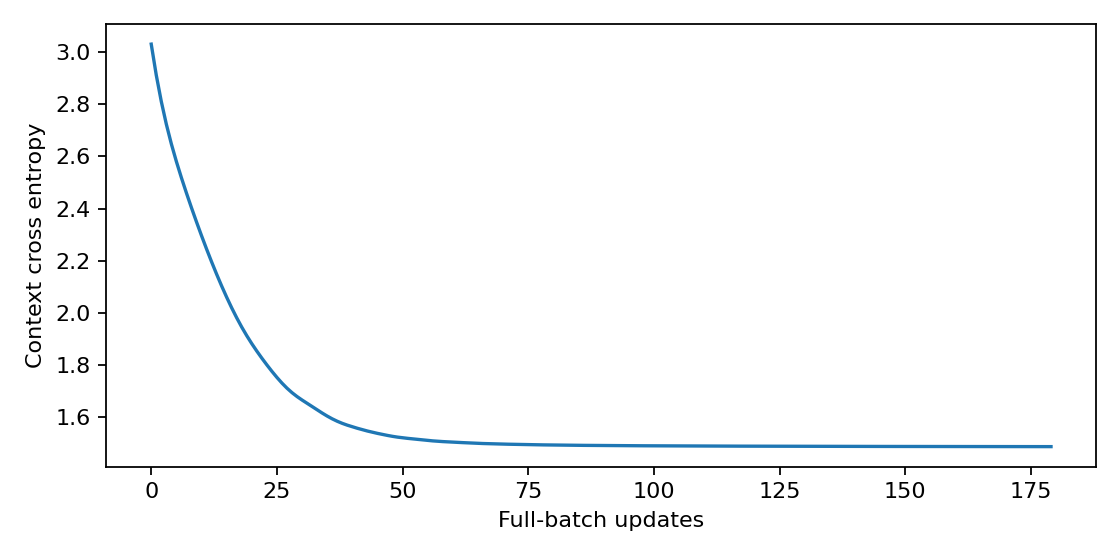

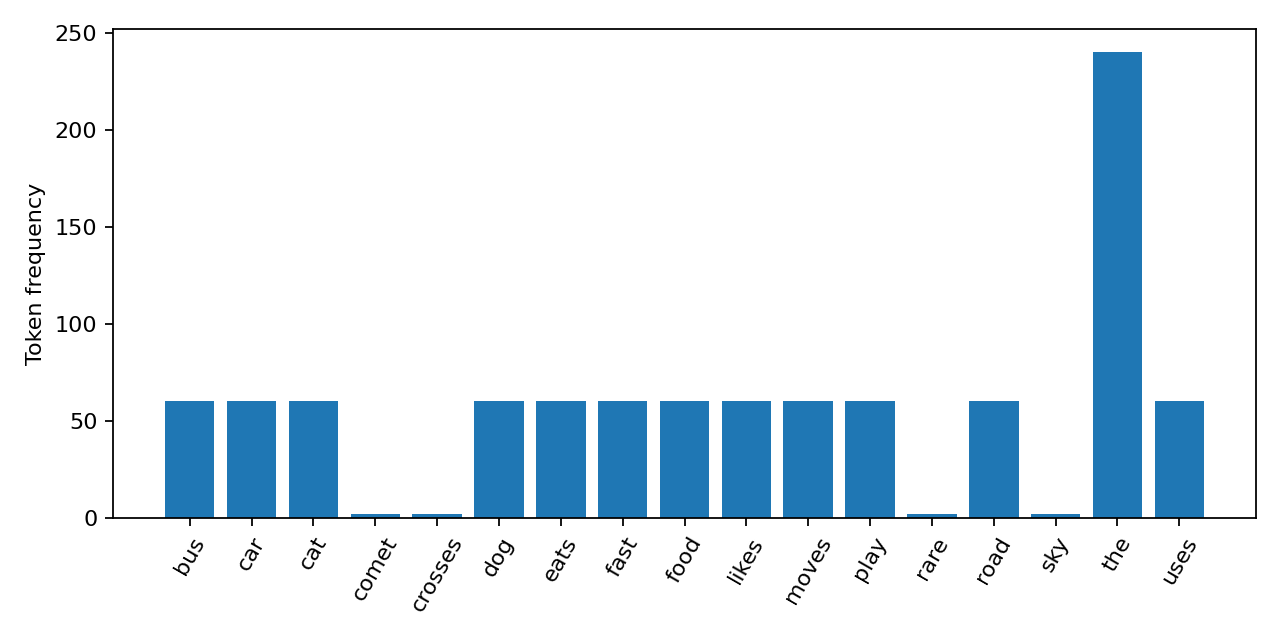

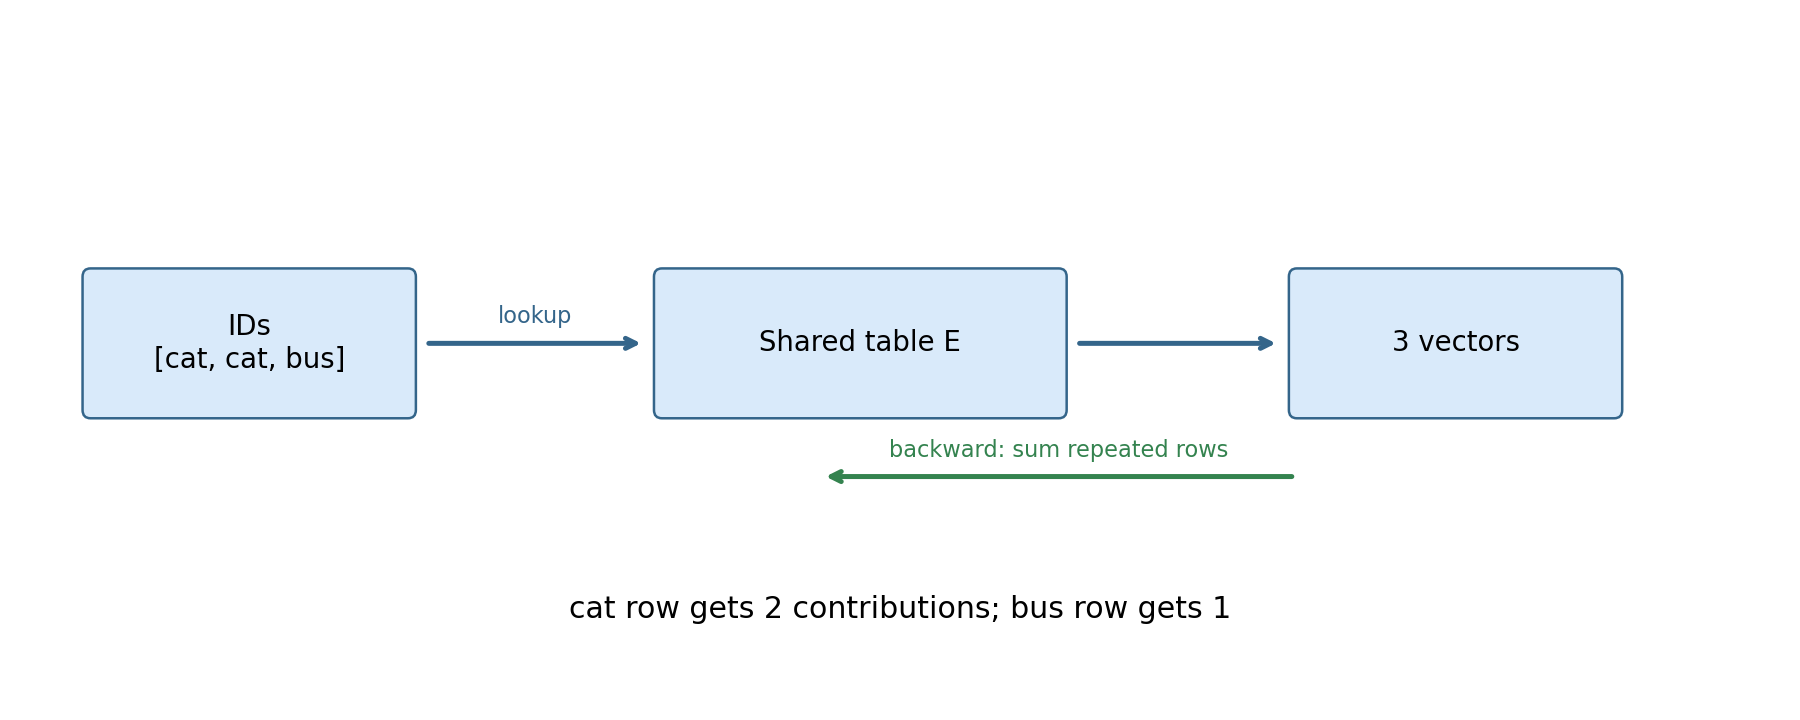

In [5]:
from IPython.display import display, Image
for p in sorted(pathlib.Path('figures').glob('*.png')):
    print(p.name)
    display(Image(filename=str(p)))

解释任务：逐项说明图中的控制变量、预算口径、失败对照和不能支持的结论。详细答案见answers.md。